# TP Ciencia de Datos — Predicción del puntaje de reseñas de Letterboxd

**Ciencia de Datos · 2do Cuatrimestre 2026**

**Integrantes:**

Arce Milagros, Contreras Mora, Di Santo Ramiro, Melchiori Lautaro, Rizzitano Lautaro

---

## Objetivo

Queremos predecir el puntaje (`Rating`, de 0.5 a 5 estrellas) que un usuario le pone a una película a partir del texto de su reseña.

In [38]:
!pip install -q emoji
!pip install -q nltk


In [39]:
import os
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
import nltk
from scipy.sparse import hstack, csr_matrix

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV, GroupShuffleSplit, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, mean_absolute_error, f1_score, confusion_matrix,
                             cohen_kappa_score, make_scorer)
from nltk.stem import SnowballStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer



# 1. Carga de Datos




In [40]:
df = pd.read_csv('./letterboxd_250movie_reviews.csv')
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (90016, 6)


,Unnamed: 0,Review,Rating,Date,Status,Movie
0,0,I am an idiot. Why is it that I still dread wa...,★★★★★,01 Dec 2013,Watched,harakiri
1,1,honor in the individual is virtue honor in a s...,★★★★★,18 Jan 2022,NaN,harakiri
2,2,Brilliant. Riveting exploration of mortality a...,NaN,26 Jan 2024,Watched,harakiri
3,3,God damn what an impeccable film. Not dated in...,★★★★★,21 Jun 2021,Watched,harakiri
4,4,95First thing's first: giving a big thanks to ...,★★★★★,06 Sep 2020,Watched,harakiri


# 2. Exploración del dataset




## 2.1 Rating


In [41]:
df = df.drop(columns='Unnamed: 0')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90016 entries, 0 to 90015
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Review  90011 non-null  str  
 1   Rating  86513 non-null  str  
 2   Date    90016 non-null  str  
 3   Status  86858 non-null  str  
 4   Movie   90016 non-null  str  
dtypes: str(5)
memory usage: 3.4 MB


- `Unnamed: 0` es el índice que se guardó al exportar el CSV, no es información → la borramos.
- Todas las columnas son texto, `Rating` viene como estrellas y `Date` como texto, así que hay que convertirlas.

In [42]:
df['Rating'].value_counts(dropna=False)

Rating
★★★★★    41077
★★★★½    21031
★★★★     15031
★★★½      4411
NaN       3503
★★★       2380
★★½        892
★★         737
½          340
★          320
★½         294
Name: count, dtype: int64

In [43]:
def estrellas_a_numero(s):
    if pd.isna(s):
        return np.nan
    return s.count('★') + 0.5 * s.count('½')

df['y'] = df['Rating'].map(estrellas_a_numero)
# sacamos la columna de estrellitas
df = df.drop(columns=['Rating'])

conteo = df['y'].value_counts().sort_index()
porcentaje = (100 * conteo / conteo.sum()).round(2)
print('Clases distintas:', df['y'].nunique())
pd.DataFrame({'reseñas': conteo, '%': porcentaje})


Clases distintas: 10


,reseñas,%
y,,
0.5,340,0.39
1.0,320,0.37
1.5,294,0.34
2.0,737,0.85
2.5,892,1.03
3.0,2380,2.75
3.5,4411,5.10
4.0,15031,17.37
4.5,21031,24.31


In [44]:
print('Reseñas sin puntaje:', df['y'].isna().sum())

Reseñas sin puntaje: 3503


**Analisis de Rating:**
- Hay 10 clases (0.5, 1, 1.5, … , 5). Es una variable ordinal, tiene orden, 4.5 está más cerca de 5 que de 1.
- El dataset está muy desbalanceado, casi la mitad de las reseñas son de 5 y aproximadamente el 86% tienen 4 o más.
- Las medias estrellas se usan igual que las enteras, 4.5 es la segunda clase más frecuente y 3.5 tiene más reseñas que 3.

**¿Cómo afecta al modelo?**
- Un modelo que siempre dice 5 acierta el 47% sin aprender nada. El accuracy va a estar inflado.
- Las clases bajas (0.5 a 2.5) tienen muy pocos ejemplos, así que probablemente al modelo le cueste predecirlas.
- Equivocarse por media estrella (4.5 en vez de 5) no es tan grave como equivocarse por 4 estrellas, pero el accuracy cuenta los dos errores igual. Por eso vamos a usar una métrica que tenga en cuenta el orden como QWK, MAE y RMSE.

**Reseñas sin puntaje**

Las reseñas sin puntaje no conviene rellenarlas con la media o la moda porque invertarle un valor provocaría un sesgo en el modelo, ademas que al estar tan desbalanceadas las clases usar eso para rellenar datos solo aumentaria las desproporcion del dataset, asi que decidimos sacarlas del mismo.



## 2.2 Análisis inicial

In [45]:
print('Cantidad de reseñas:', len(df))
print('Cantidad de películas distintas:', df['Movie'].nunique())
print('\nValores faltantes:')
print(df.isna().sum())

print('Filas duplicadas exactas:', df.duplicated().sum())
print('Reseñas con el mismo texto:', df['Review'].duplicated().sum())
print('\nTextos más repetidos:')
df.loc[df['Review'].duplicated(keep=False), 'Review'].value_counts().head(8)

texto = df['Review'].fillna('')
palabras = texto.str.split().str.len()
print('Reseñas vacías:', df['Review'].isna().sum())
print('Reseñas de una sola palabra:', (palabras == 1).sum())
palabras.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1)

# sacamos las reseñas sin puntaje
df = df.dropna(subset=['y'])

Cantidad de reseñas: 90016
Cantidad de películas distintas: 250

Valores faltantes:
Review       5
Date         0
Status    3158
Movie        0
y         3503
dtype: int64
Filas duplicadas exactas: 4
Reseñas con el mismo texto: 216

Textos más repetidos:
Reseñas vacías: 5
Reseñas de una sola palabra: 605


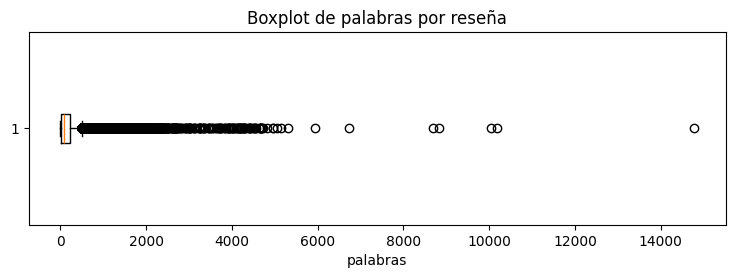

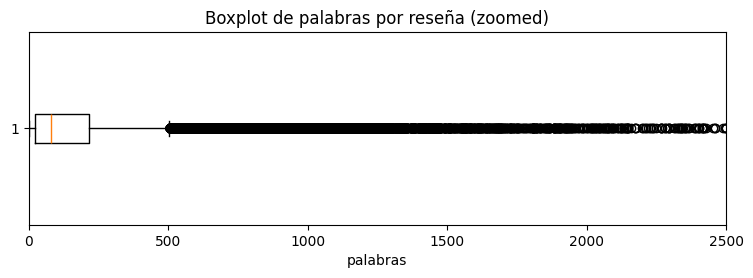

In [46]:
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.boxplot(palabras, vert=False)
ax.set_title('Boxplot de palabras por reseña'); ax.set_xlabel('palabras')
plt.show()


fig, ax = plt.subplots(figsize=(9, 2.5))
ax.boxplot(palabras, vert=False)
ax.set_xlim(0, 2500)
ax.set_title('Boxplot de palabras por reseña (zoomed)'); ax.set_xlabel('palabras')
plt.show()

In [47]:
mediana = palabras.median()

print(f"Mediana de palabras por reseña: {mediana:.0f}")

Mediana de palabras por reseña: 82


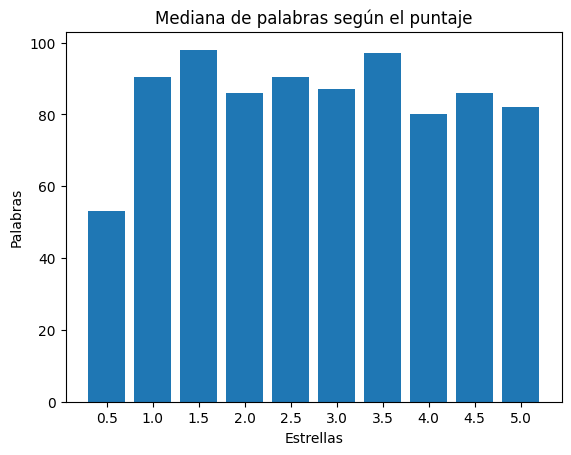

In [48]:
largo_por_puntaje = df.dropna(subset=['y']).assign(palabras=palabras).groupby('y')['palabras'].median()
fig, ax = plt.subplots()
ax.bar(largo_por_puntaje.index.astype(str), largo_por_puntaje.values)
ax.set_title('Mediana de palabras según el puntaje'); ax.set_xlabel('Estrellas'); ax.set_ylabel('Palabras')
plt.show()

Solo hay 4 filas duplicadas exactas que las interpretamos como errores en la generación del dataset, por ende las borramos.

Los textos repetidos son casi todos reseñas cortas como "Great" o "Masterpiece.", escritas por distintos usuarios (tienen distinta fecha y puntaje). Esas no son duplicados, así que las dejamos.

Al ser la reseña el input al partir el cual el modelo va a realizar su predicción, decidimos eliminar las 5 filas que tienen este campo vacio. Por otro lado, las reseñas de una sola palabra consideramos que son utiles para el modelo ya que pueden contener terminos muy polarizados como "Masterpice" de las que se pueden deducir fácilmente lo que quieren expresar.

Las reseñas de 0.5 son algo más cortas, pero en el resto la longitud es parecida. La longitud sola no parece decir mucho del puntaje. Por ende, no será tenida en cuenta como feature.


In [49]:
# limpiamos las filas sin review
df = df.dropna(subset=['Review'])

# 3. Análisis de las variables disponibles


## 3.1 Movie

       Valor                        Significado
count  250.0                  Películas totales
mean   346.0   Promedio de reseñas por película
std      8.2                Desviación estándar
min    260.0  Mínimo de reseñas en una película
25%    343.0                       Percentil 25
50%    347.0                            Mediana
75%    351.0                       Percentil 75
max    359.0  Máximo de reseñas en una película



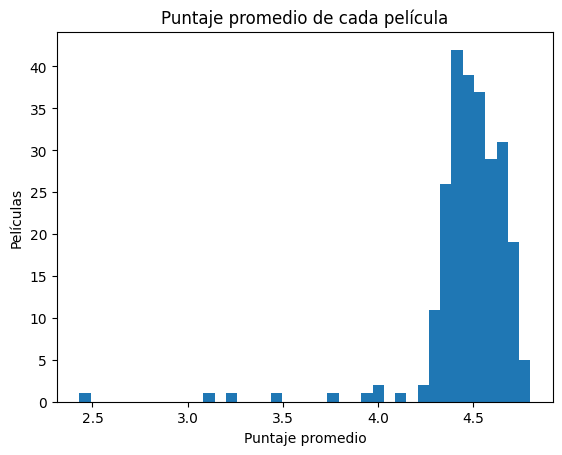

In [50]:
por_peli = df.groupby('Movie')['y'].agg(['mean', 'count'])

estadisticas = por_peli['count'].describe().round(1).to_frame(name='Valor')
explicaciones = {
    'count': 'Películas totales',
    'mean': 'Promedio de reseñas por película',
    'std': 'Desviación estándar',
    'min': 'Mínimo de reseñas en una película',
    '25%': 'Percentil 25',
    '50%': 'Mediana',
    '75%': 'Percentil 75',
    'max': 'Máximo de reseñas en una película'
}
estadisticas['Significado'] = estadisticas.index.map(explicaciones)
print(estadisticas)
print()

fig, ax = plt.subplots()
ax.hist(por_peli['mean'], bins=40)
ax.set_title('Puntaje promedio de cada película'); ax.set_xlabel('Puntaje promedio'); ax.set_ylabel('Películas')
plt.show()


- Hay unas 360 reseñas por película, así que en ese sentido está balanceado.
- La mayoría de las películas tiene un promedio alrededor de 4.5, salvo algunas pocas que dan bastante menos.

**¿Usamos la película como feature?**
- A favor: algunas películas tienen promedios distintos y eso podría ayudar.
- En contra: si llega una reseña de una película que no está en el dataset, el modelo no tendría esa información.

Queremos un modelo que funcione para cualquier película, por eso decidimos no usar `movie` como feature.



In [51]:
df = df.drop(columns=['Movie'])

## 3.2 Date

In [52]:
anio = df['Date'].str.split().str[-1].astype(int)
print('Año mínimo:', anio.min(), '| Año máximo:', anio.max())
print('\nAños raros:')

conteo = anio[(anio < 2011) | (anio > 2024)].value_counts().sort_index()

items = [f"{anio}: {cant}" for anio, cant in conteo.items()]

for i in range(0, len(items), 4):
    fila = items[i:i + 4]
    print("  |  ".join(f"{item:<14}" for item in fila))

Año mínimo: 4 | Año máximo: 2566

Años raros:
4: 1            |  1896: 1         |  1948: 1         |  1951: 1       
1952: 2         |  1955: 1         |  1957: 4         |  1961: 1       
1963: 2         |  1966: 1         |  1971: 1         |  1983: 1       
1985: 1         |  1987: 1         |  1992: 1         |  1993: 2       
1994: 5         |  1995: 6         |  1996: 1         |  1997: 2       
1998: 3         |  1999: 5         |  2000: 5         |  2001: 5       
2002: 4         |  2003: 2         |  2004: 11        |  2005: 12      
2006: 13        |  2007: 14        |  2008: 12        |  2009: 4       
2010: 21        |  2562: 1         |  2565: 1         |  2566: 2       


Con respecto al campo de la fecha notamos los siguientes inconvenientes:

*   Fechas previas a la creación de letterbox (2011)
*   Fechas futuristas

Para el análisis de `date` como feature no seran tenidas en cuentas. No borramos esas reseñas porque el texto está bien.


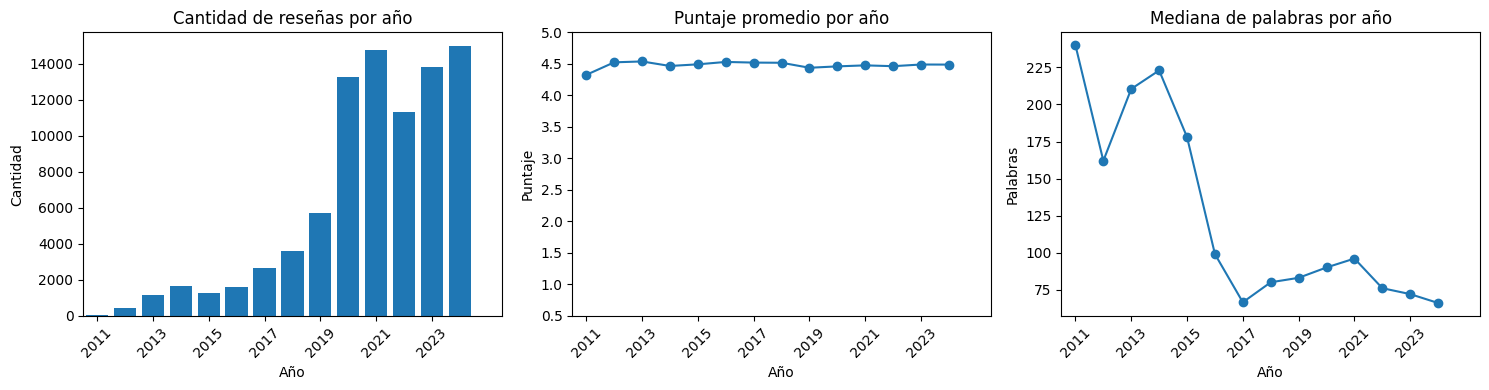

,reseñas,puntaje_medio,palabras_mediana
anio,,,
2011,40,4.32,240.0
2012,435,4.52,162.0
2013,1134,4.54,210.5
2014,1655,4.47,223.0
2015,1283,4.49,178.0
2016,1618,4.53,99.0
2017,2644,4.52,66.5
2018,3600,4.52,80.0
2019,5727,4.44,83.0


In [53]:
df_fechas = df[anio.between(2011, 2024)].copy()
df_fechas["anio"] = anio[anio.between(2011, 2024)]

por_anio = df_fechas.groupby("anio").agg(
    reseñas=("y", "size"),
    puntaje_medio=("y", "mean"),
    palabras_mediana=(
        "Review",
        lambda s: s.fillna("").str.split().str.len().median()
    )
)

por_anio = por_anio.reindex(range(2011, 2025))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(por_anio.index, por_anio["reseñas"].fillna(0))
axes[0].set_title("Cantidad de reseñas por año")
axes[0].set_ylabel("Cantidad")

axes[1].plot(por_anio.index, por_anio["puntaje_medio"], marker="o")
axes[1].set_title("Puntaje promedio por año")
axes[1].set_ylabel("Puntaje")
axes[1].set_ylim(0.5, 5)

axes[2].plot(por_anio.index, por_anio["palabras_mediana"], marker="o")
axes[2].set_title("Mediana de palabras por año")
axes[2].set_ylabel("Palabras")

for ax in axes:
    ax.set_xlim(2010.5, 2025.5)
    ax.set_xticks(range(2011, 2025, 2))
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Año")

plt.tight_layout()
plt.show()

display(por_anio.round(2))



* La mayoría de las reseñas son de 2020 en adelante.
* El puntaje promedio casi no cambia con los años (siempre ronda 4.5).
* La longitud sí cambia, en los años más recientes las reseñas son más cortas.

Conclusión: Como vimos anteriormente la longitud de la reseña no influye en el puntaje. Por ende, al ser la longitud de la reseña lo unico que varia con el tiempo la fecha tampoco sera tenida en cuenta como feature.


In [54]:
# eliminamos Date
df = df.drop(columns=['Date'])

## 3.3. Status

             count   mean
Status                   
Desconocido   2978  4.366
Rewatched    22434  4.759
Watched      61096  4.379


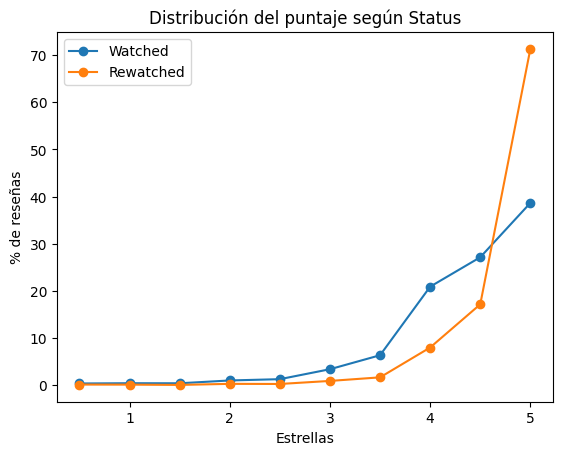

In [55]:
df['Status'] = df['Status'].fillna('Desconocido')
print(df.groupby('Status')['y'].agg(['count', 'mean']).round(3))

tabla_status = pd.crosstab(df['Status'], df['y'], normalize='index') * 100
fig, ax = plt.subplots()
ax.plot(tabla_status.columns, tabla_status.loc['Watched'], marker='o', label='Watched')
ax.plot(tabla_status.columns, tabla_status.loc['Rewatched'], marker='o', label='Rewatched')
ax.set_title('Distribución del puntaje según Status'); ax.set_xlabel('Estrellas'); ax.set_ylabel('% de reseñas')
ax.legend(); plt.show()

- `Status` dice si el usuario vio la película por primera vez (Watched) o si la volvió a ver (Rewatched). Hay 3.200 sin dato, que pusimos como "Desconocido".
- Las reseñas Rewatched tienen un promedio de 4.76 contra 4.38 de las Watched. Tiene sentido ya que uno vuelve a ver las películas que le gustaron (conocimiento del dominio).

Decidimos usar `Status` como feature ya que tiene poder explicativo sobre la variable a predecir y la encodeamos con one-hot encoding , dejando "Desconocido" como una categoría más. Codificamos con one-hot de manera que el modelo no establezca una jerarquia entre las categorias.

Cabe destacar que esta feature podría generar un sesgo en el modelo provocando que tienda a predecir puntajes muy altos solo por ser Rewatched, incluso en casos donde la reseña sea notablemente negativa. Es por eso que vamos a evaluar el modelo con y sin esta feature.

In [56]:
df = pd.get_dummies(
    df,
    columns=['Status'],
    prefix='Status',
    dtype=int,
    drop_first=False, # esto habria que cambiarlo para modelos de regresion lineal/logistica para evitar la colinealidad perfecta, en modelos de arbol conviene mantenerlo False
)

print(df)


                                                  Review    y  \
0      I am an idiot. Why is it that I still dread wa...  5.0   
1      honor in the individual is virtue honor in a s...  5.0   
3      God damn what an impeccable film. Not dated in...  5.0   
4      95First thing's first: giving a big thanks to ...  5.0   
5      Probably the greatest film ever.. a film about...  5.0   
...                                                  ...  ...   
90011  "I'm speaking of my suffering. I'm not acting....  4.5   
90012  Damn, what a complex film. I actually have no ...  4.0   
90013  “When spite comes along, art dons a veil”Passi...  5.0   
90014  Arguably the most simply distilled expression ...  5.0   
90015  Close-Up (1990)Kalo udah selesai nonton film y...  5.0   

       Status_Desconocido  Status_Rewatched  Status_Watched  
0                       0                 0               1  
1                       1                 0               0  
3                       0        

# Split del dataset

Como ya decidimos no tener en cuenta el atributo `Movie` ni el atributo `Date` por los motivos antes explicados, descartamos hacer un split por Pelicula y un split Temporal (por fechas).

Es por esto que elegimos hacer una división aleatoria, aunque debido a la gran desproporcición de las clases en el dataset decidimos aplicar la técnica de estratificación, garantizando que todas las clases aparezcan en igual proporción en train y test.

Separamos tres conjuntos:
- **Test (20%)**: no lo tocamos hasta el final. Lo usamos **una sola vez** para medir el modelo elegido.
- **Validación (10%)**: reseñas del train para comparar alternativas y elegir hiperparámetros.
- **Entrenamiento (70%)**: lo usaremos para entrenar el modelo. Ya que entrenar con ~70.000 reseñas puede tardar mucho, hacemos una muestra de 30.000 para comparar y probar modelos, y para el resultado final entrenaremos con todas las reseñas de entrenamiento.

In [57]:
X = df.drop(columns=['y'])
y = df['y']

RANDOM_STATE = 42

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

val_relative_size = 0.10 / 0.80  # para separar el conjunto de validacion que sera 10 porciento del total (pero aca lo saco del train+val que es 80 porciento del total)
                                  # => es 12.5% del train+val (0.1/0.8 = 0.125)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=val_relative_size,
    stratify=y_train_val,
    random_state=RANDOM_STATE,
)

X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train,
    y_train,
    train_size=30000,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print(f"Train completo: {len(X_train)} filas ({len(X_train)/len(X):.1%})")
print(f"Validacion:     {len(X_val)} filas ({len(X_val)/len(X):.1%})")
print(f"Test:           {len(X_test)} filas ({len(X_test)/len(X):.1%})")
print(f"Train submuestra rápida: {len(X_train_sub)} filas")

Train completo: 60555 filas (70.0%)
Validacion:     8651 filas (10.0%)
Test:           17302 filas (20.0%)
Train submuestra rápida: 30000 filas


# 4. Preprocesamiento del texto

## Como elegir procesamientos | Stopwords, Stemming, Lematizacion

Para poder usar modelos de clasificación o regresión debemos vectorizar el texto. Antes de aplicar técnicas de vectorizado como Bag of words o Tf-Idf realizamos un preproceso del texto con el fin de reducir la dimensión de los vectores resultantes y hallar features nuevas que puedan tener valor explicativo sobre el rating.

Para determinar que opciones de pre-procesado son mejores para reducir la dimensión del texto sin perder información valiosa y por lo tanto rendimiento vamos a comparar las diferentes opciones haciendo lo siguiente:
- Dada una opcion de preprocesado, se vectoriza y se clasifica con el mismo modelo rapido y se evaluan las mismas metricas. En base a eso, elegimos que opcion fue mejor.

Decidimos usar un Ridge ya que es rapido de calcular y penaliza el error cuadratico medio (es mucho mas grave errarle por 4 estrellas que por 0.5, por mas que a nivel accuracy sean igual de incorrectos). Como Ridge es una regresion, lo que hacemos es redondear (clip) a la media estrella mas cercana.

Para la metrica nos interesa el MAE como medida de la media del error absoluto (por cuantas estrellas le erra en promedio). Se calcula rapido y me da una noción de si el modelo entienda la diferencia entre una buena y una mala reseña.

Como vectorizador usamos TF-IDF ya que es mejor que el Bag of words.

In [58]:
def redondear(pred):
    """Redondea a la media estrella más cercana y lo deja entre 0.5 y 5."""
    return np.clip(np.round(pred * 2) / 2, 0.5, 5)

def metricas(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    clases_real, clases_pred = (real * 2).astype(int), (pred * 2).astype(int)
    return {
        'MAE': mean_absolute_error(real, pred),
        'Accuracy': accuracy_score(clases_real, clases_pred),
    }

def probar(vectorizador, x_train, y_train, x_validation, y_validation):
  """Vectoriza, entrena un Ridge y devuelve el rendimiento en validación y cantidad de features."""
  inicio = time.time()

  X_train_vec = vectorizador.fit_transform(x_train)
  X_val_vec = vectorizador.transform(x_validation)

  modelo = Ridge(alpha=1.0)
  modelo.fit(X_train_vec, y_train)

  predicciones = redondear(modelo.predict(X_val_vec))

  m = metricas(y_validation, predicciones)
  segundos = time.time() - inicio

  return {
      'features': X_train_vec.shape[1],
      'MAE': round(m['MAE'], 4),
      'Accuracy': round(m['Accuracy'], 4),
      'segundos': round(segundos, 2),
  }

NEGACIONES = {'not','no','nor','never','nothing','none','nobody','cannot','without'}
stopwords_todas = list(ENGLISH_STOP_WORDS)
stopwords_sin_negaciones = list(ENGLISH_STOP_WORDS - NEGACIONES)

stemmer = SnowballStemmer('english')

def tokens_con_stemming(t):
  return [stemmer.stem(w) for w in re.findall(r'\b\w\w+\b', t)]

try:
  import nltk

  nltk.download('wordnet', quiet=True) # esto puede fallar si no hay internet, por eso adentro del try
  from nltk.stem import WordNetLemmatizer

  lematizador = WordNetLemmatizer()
  lematizador.lemmatize('movies')  # Verificación operativa

  def tokens_con_lematizacion(t):
    return [lematizador.lemmatize(w) for w in re.findall(r'\b\w\w+\b', t)]

except Exception as e:
  print(f'Aviso: WordNet no disponible ({e}). Se omitirá la lematización.')
  tokens_con_lematizacion = None

# Hiperparámetros comunes para los vectorizadores
base = dict(ngram_range=(1, 2), min_df=5, sublinear_tf=True)


x_tr = X_train_sub['Review']
y_tr = y_train_sub
x_vl = X_val['Review']
y_vl = y_val

modelos_a_probar = {
    'texto original (sin lowercase)': TfidfVectorizer(lowercase=False, **base),
    'texto limpio (default lowercase)': TfidfVectorizer(
        lowercase=True, **base
    ),
    'limpio, sin stopwords': TfidfVectorizer(
        stop_words=stopwords_todas, **base
    ),
    'limpio, sin stopwords (dejando negaciones)': TfidfVectorizer(
        stop_words=stopwords_sin_negaciones, **base
    ),
    'limpio + stemming': TfidfVectorizer(
        tokenizer=tokens_con_stemming, token_pattern=None, **base
    ),
}

if tokens_con_lematizacion is not None:
  modelos_a_probar['limpio + lematización'] = TfidfVectorizer(
      tokenizer=tokens_con_lematizacion, token_pattern=None, **base
  )

# Ejecución y consolidación en DataFrame
resultados = {}
for nombre, vec in modelos_a_probar.items():
  resultados[nombre] = probar(vec, x_tr, y_tr, x_vl, y_vl)

df_resultados = pd.DataFrame(resultados).T
print(df_resultados)

                                            features     MAE  Accuracy  \
texto original (sin lowercase)              153315.0  0.4190    0.3701   
texto limpio (default lowercase)            149850.0  0.4190    0.3709   
limpio, sin stopwords                        78666.0  0.4242    0.3730   
limpio, sin stopwords (dejando negaciones)   80691.0  0.4212    0.3737   
limpio + stemming                           141051.0  0.4186    0.3704   
limpio + lematización                       146226.0  0.4186    0.3712   

                                            segundos  
texto original (sin lowercase)                 17.23  
texto limpio (default lowercase)               16.53  
limpio, sin stopwords                          11.88  
limpio, sin stopwords (dejando negaciones)     11.80  
limpio + stemming                              34.82  
limpio + lematización                          33.20  


Como podemos ver, la eliminación de Stopwords reduce el vocabulario a casi la mitad, pero a costo de aumentar el MAE. Parece ser que es informacion valiosa que no queremos perder. Eliminar stopwords pero mantener las negaciones mejora un poco el error, por lo que parece ser que esas stopwords son particularmente importantes, pero sigue siendo un error considerablemente mayor a no eliminar nada, a cambio de unos pocos segundos de diferencia en rendimiento. Esto puede deberse a que en ingles muchas combinaciones como "not good", "too long" , "bit boring", etc. cambian el significado de la frase totalmente.

=> **Mantenemos las stopwords, la reduccion en computo y tamaño de vocabulario no justifica la perdida de rendimiento**

Con respecto al stemming y la lematizacion vemos que alcanzan el minimo MAE de toda la tabla, pero la mejora de rendimiento es marginal respecto al costo computacional que es 3 veces mayor a no aplicar estas tecnicas. Con tantas reseñas, puede que cada forma de las palabras aparezca lo suficiente para que el modelo las aprenda y no le cambie el hecho de agruparlas aplicando stemming/lematizacion.

=> **No aplicaremos Stemming ni Lematizacion, no se justifica la ganancia marginal de rendimiento frente al alto costo computacional**

## Elegir Vectorizador

Probamos cambiar un parámetro por vez para ver cuántas features genera y si mejora:
- `ngram_range`: (1,1) solo palabras sueltas; (1,2) también pares de palabras (bigramas).
- `min_df`: saca las palabras que aparecen en menos de N reseñas.
- `max_df`: saca las palabras que aparecen en más de cierto % de las reseñas.
- `max_features`: se queda solo con las N palabras más frecuentes.

In [59]:
vectorizadores = {
    'BoW (CountVectorizer), unigramas': CountVectorizer(min_df=5),
    'TF-IDF unigramas': TfidfVectorizer(min_df=5, sublinear_tf=True),
    'TF-IDF unigramas + bigramas': TfidfVectorizer(
        ngram_range=(1, 2), min_df=5, sublinear_tf=True
    ),
    'TF-IDF hasta trigramas': TfidfVectorizer(
        ngram_range=(1, 3), min_df=5, sublinear_tf=True
    ),
    'TF-IDF (1,2) min_df=1': TfidfVectorizer(
        ngram_range=(1, 2), min_df=1, sublinear_tf=True
    ),
    'TF-IDF (1,2) min_df=20': TfidfVectorizer(
        ngram_range=(1, 2), min_df=20, sublinear_tf=True
    ),
    'TF-IDF (1,2) min_df=5 max_df=0.5': TfidfVectorizer(
        ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True
    ),
    'TF-IDF (1,2) max_features=5000': TfidfVectorizer(
        ngram_range=(1, 2), max_features=5000, sublinear_tf=True
    ),
    'TF-IDF (1,2) max_features=50000': TfidfVectorizer(
        ngram_range=(1, 2), max_features=50000, sublinear_tf=True
    ),
}

resultados_vec = {}
for nombre, vec in vectorizadores.items():
  resultados_vec[nombre] = probar(vec, x_tr, y_tr, x_vl, y_vl)

df_resultados_vec = pd.DataFrame(resultados_vec).T.sort_values(by='MAE')
print(df_resultados_vec)

                                   features     MAE  Accuracy  segundos
TF-IDF (1,2) min_df=1             1682393.0  0.4116    0.3756     24.71
TF-IDF hasta trigramas             229767.0  0.4181    0.3690     27.68
TF-IDF unigramas + bigramas        149850.0  0.4190    0.3709     15.99
TF-IDF (1,2) min_df=5 max_df=0.5   149841.0  0.4197    0.3700     16.02
TF-IDF (1,2) max_features=50000     50000.0  0.4231    0.3743     21.57
TF-IDF (1,2) min_df=20              39340.0  0.4245    0.3743     15.07
TF-IDF unigramas                    32324.0  0.4291    0.3664      5.44
TF-IDF (1,2) max_features=5000       5000.0  0.4421    0.3571     20.55
BoW (CountVectorizer), unigramas    32324.0  0.5879    0.3264     43.70


- **TF-IDF funciona mucho mejor que Bag of Words.** TF-IDF le baja el peso a palabras que aparecen en todas las reseñas ("film", "movie") y normaliza cada reseña, así que no depende del largo. Con BoW, una reseña de 5.000 palabras tiene conteos enormes comparada con una de 5, y eso confunde al modelo (por eso el error da tan alto).
- **Agregar bigramas mejora bastante**, porque captura cosas como "not good", "must watch" o "fell asleep". Agregar trigramas mejora apenas y suma unas 80.000 features más.
- **`min_df` es el que más cambia la cantidad de features**: con `min_df=1` aparecen millones de bigramas que están una sola vez, sin mejorar casi nada. Con `min_df=5` el vocabulario es mucho más chico.
- `max_df` casi no cambia nada: hay muy pocas palabras que aparezcan en más de la mitad de las reseñas.
- Con `max_features=5000` se pierde bastante. Con 50.000 se pierde poco: es útil para modelos lentos.
- En todos usamos sublinear tf que hace que el term frecuency se cuente con un logaritmo ya que hay bastante disparidad en las longitudes totales de los textos y usar una escala lineal para el tf hace que se le de mucha mas importancia a ciertos terminos en un texto largo solo por ser largo, la escala logaritmica mitiga esto

=> Elegimos `TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)`


## Preprocesamiento de emojis

In [60]:
cant_emojis = texto.map(emoji.emoji_count)
print('Reseñas con emojis:', (cant_emojis > 0).sum(), f'({100 * (cant_emojis > 0).mean():.1f}%)')

Reseñas con emojis: 5991 (6.7%)


Aproximadamente el 7% de las reseñas tiene emojis. Ahora miramos cómo se reparten por clase y cuáles son los más usados en cada una.

In [61]:
lista_emojis = df['Review'].map(lambda t: [e['emoji'] for e in emoji.emoji_list(t)])
cant = lista_emojis.str.len()
print('% de reseñas con al menos un emoji, por clase:')
print({clase: f'{pct}%' for clase, pct in (cant > 0).groupby(df['y']).mean().mul(100).round(1).to_dict().items()})

grupos_puntaje = pd.cut(df['y'], [0, 2, 3.5, 4, 4.5, 5], labels=['0.5–2', '2.5–3.5', '4', '4.5', '5'])
top_emojis = {}
for g in grupos_puntaje.cat.categories:
    en_grupo = lista_emojis[grupos_puntaje == g]
    c = Counter(e for l in en_grupo for e in set(l))          # set: contamos en cuántas reseñas aparece
    top_emojis[f'{g} ({len(en_grupo)} reseñas)'] = [f'{e} {100 * n / len(en_grupo):.2f}%' for e, n in c.most_common(8)]
pd.DataFrame(top_emojis)

% de reseñas con al menos un emoji, por clase:
{0.5: '4.1%', 1.0: '6.9%', 1.5: '5.4%', 2.0: '5.6%', 2.5: '6.2%', 3.0: '6.9%', 3.5: '6.9%', 4.0: '6.6%', 4.5: '6.8%', 5.0: '6.8%'}


,0.5–2 (1691 reseñas),2.5–3.5 (7681 reseñas),4 (15031 reseñas),4.5 (21028 reseñas),5 (41077 reseñas)
0,😭 0.53%,😭 0.53%,😭 0.49%,😭 0.52%,😭 0.55%
1,😴 0.30%,👍 0.36%,🔜 0.31%,🔙 0.37%,🔙 0.52%
2,👀 0.24%,🔜 0.36%,🔙 0.24%,🔜 0.33%,❤️ 0.51%
3,™ 0.24%,⭐ 0.35%,❤️ 0.23%,❤️ 0.32%,🔜 0.41%
4,😔 0.24%,🔙 0.33%,⭐ 0.21%,🏆 0.28%,💯 0.26%
5,😡 0.18%,❤️ 0.27%,😂 0.20%,✅ 0.19%,🏆 0.24%
6,🤷‍♀️ 0.18%,😂 0.22%,✅ 0.17%,😍 0.18%,⭐ 0.18%
7,🥴 0.18%,🇧🇷 0.20%,💔 0.17%,💔 0.17%,💔 0.17%


Aclaración: Agrupamos las clases bajas ya que tienen pocas reseñas.

- El porcentaje de reseñas con emojis es parecido en casi todas las clases. Solo 0.5 tiene menos.
- 😭 es el más usado en todas las clases, lo que lo hace ambiguo.
- ❤️, 💯 y 🏆 aparecen sobre todo en 4.5 y 5. En las clases bajas aparecen 😴, 😔 y 😡, pero en muy pocas reseñas.
- 🔙 y 🔜 se usan para representar películas que los usuarios ya vieron y aquellas que esperan ver en el futuro, no expresan sentimiento.

Si bien aparecen en un porcentaje relativamente bajo de las reseñas totales, concluímos que los emojis aportan información útil, especialmente viendo que existe una relación entre los tipos de emojis usado y el puntaje de la reseña. Por lo que, en vez de contemplarlos como features nuevas (lo que agrega complejidad para codificarlos mediante, por ejemplo, one-hot encoding), decidimos traducirlos a un texto representativo dentro de la misma review, de manera que sea vectorizado de la misma manera que el resto del texto y se contemple su semántica como parte del vocabulario de palabras.

In [62]:


# Identificamos primero las filas que originalmente contienen emojis para poder mostrar el ejemplo después
filas_con_emojis_idx = X_train[X_train['Review'].map(emoji.emoji_count) > 0].index

# Convertimos los emojis a texto utilizando demojize en la columna 'Review' de los subdatasets
X_train['Review'] = X_train['Review'].map(lambda t: emoji.demojize(t) if pd.notna(t) else t)
X_test['Review'] = X_test['Review'].map(lambda t: emoji.demojize(t) if pd.notna(t) else t)
X_val['Review'] = X_val['Review'].map(lambda t: emoji.demojize(t) if pd.notna(t) else t)
X_train_sub['Review'] = X_train_sub['Review'].map(lambda t: emoji.demojize(t) if pd.notna(t) else t)

# Mostramos un ejemplo de las reseñas convertidas utilizando los índices identificados previamente
display(df_comparacion_features.loc[filas_con_emojis_idx, ['Review']].head())

NameError: name 'df_comparacion_features' is not defined

# 4. Ingeniería de features


Para realizar el análisis de las features disponibles, hacemos una copia del dataset sobre el que agregar las nuevas columnas para luego comparar la performance de cada una sobre un modelo de prueba y elegir solo aquellas que mejoren la métrica para agregar al dataset original

In [90]:
# Copiamos para no modificar el subdataset original
df_comparacion_features = X_train_sub.copy()
df_comparacion_features_val = X_val.copy()

## 4.1 Textos en otro idioma

In [91]:
def es_ingles(t):
    ws = re.findall(r'[^\W\d_]+', t.lower())
    if len(ws) < 5:
        return 'muy corta'
    prop = sum(w in ENGLISH_STOP_WORDS for w in ws) / len(ws)
    return 'inglés' if prop >= 0.12 else 'otro idioma'

df['idioma'] = texto.map(es_ingles)
print('\n', df['idioma'].value_counts())


 idioma
inglés         77424
otro idioma     6245
muy corta       2839
Name: count, dtype: int64


Un 7% de las reseñas está en otro idioma (portugués, español, alemán, árabe, turco, etc). Lo detectamos viendo qué proporción de las palabras son stopwords en inglés.

Decidimos dejar todos los idiomas. Son pocas, y en la plataforma real también van a llegar reseñas en otros idiomas. Al final vamos a medir aparte cómo le va al modelo sin ellas.

## 4.2 Signos de exclamación y de interrogación





Segun lo que debatimos creemos como hipotesis que muchos "????" indican una reseña mala (confusión, enojo), muchos "!!!!" pueden ser ironía o mucha emoción, y un "!" suelto es un intensificador ya sea para bien o para mal.

Como la mayoría de las reseñas no tiene ninguno de estos signos, en vez de mirar promedios (que dan casi 0) miramos qué porcentaje de las reseñas de cada clase tiene al menos uno y, entre las que tienen, cuántos tienen en promedio.

% de TODAS las reseñas con al menos uno: {'!_suelto': 15.5, '!!_o_mas': 2.8, '?_suelto': 18.1, '??_o_mas': 1.0}


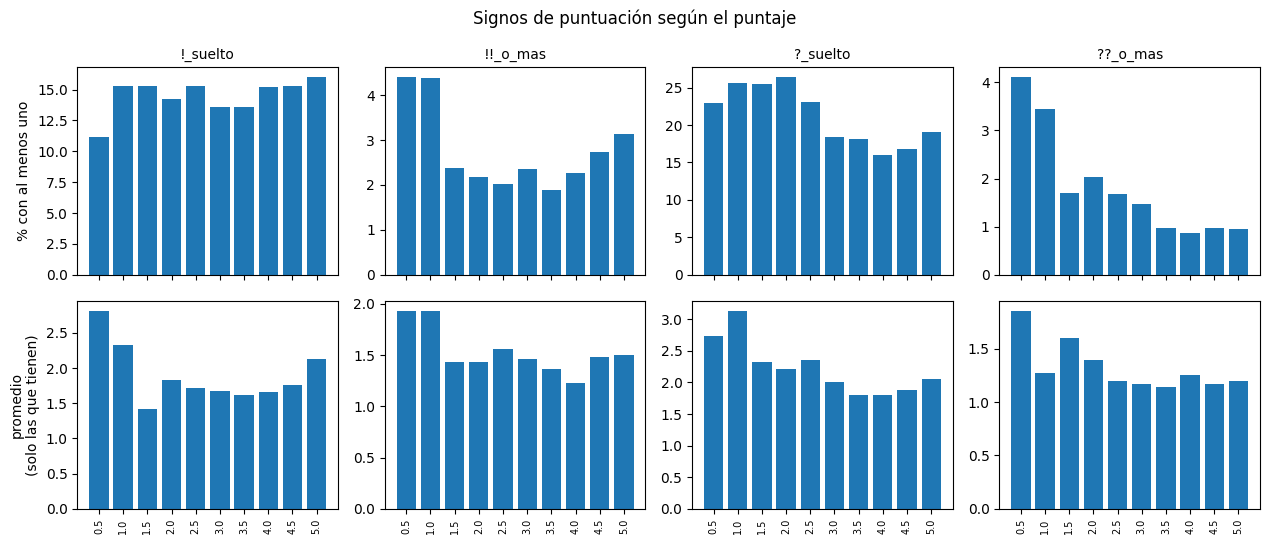

,!_suelto,!!_o_mas,?_suelto,??_o_mas
y,,,,
0.5,11.2,4.4,22.9,4.1
1.0,15.3,4.4,25.6,3.4
1.5,15.3,2.4,25.5,1.7
2.0,14.2,2.2,26.5,2.0
2.5,15.3,2.0,23.1,1.7
3.0,13.6,2.4,18.4,1.5
3.5,13.6,1.9,18.1,1.0
4.0,15.2,2.3,16.0,0.9
4.5,15.3,2.7,16.8,1.0


In [92]:
estrellas = np.arange(1, 11) / 2

def contar_signos(t):
    # Buscamos cada racha de signos iguales y la clasificamos
    c = {'!_suelto': 0, '!!_o_mas': 0, '?_suelto': 0, '??_o_mas': 0}
    # Escapamos el signo de interrogación (\?) para que se interprete como caracter literal
    for racha in re.findall(r'!+|\?+', t):
        if racha[0] == '!':
            c['!_suelto' if len(racha) == 1 else '!!_o_mas'] += 1
        else:
            c['?_suelto' if len(racha) == 1 else '??_o_mas'] += 1
    return c

def graficar_por_clase(conteos, y, titulo):
    # Arriba: % de reseñas de cada clase con al menos uno. Abajo: promedio solo entre las que tienen.
    fig, axes = plt.subplots(2, conteos.shape[1], figsize=(3.2 * conteos.shape[1], 5.5), sharex=True)
    for j, col in enumerate(conteos.columns):
        tiene = conteos[col] > 0
        pct = tiene.groupby(y).mean() * 100
        prom = conteos[col][tiene].groupby(y[tiene]).mean()
        axes[0, j].bar(pct.index.astype(str), pct.values); axes[0, j].set_title(col, fontsize=10)
        axes[1, j].bar(prom.index.astype(str), prom.values)
        axes[1, j].tick_params(axis='x', labelsize=7, rotation=90)
    axes[0, 0].set_ylabel('% con al menos uno'); axes[1, 0].set_ylabel('promedio\n(solo las que tienen)')
    plt.suptitle(titulo); plt.tight_layout(); plt.show()
    return (conteos > 0).groupby(y).mean().mul(100).round(1)

inicio = time.time()
signos = pd.DataFrame([contar_signos(t) for t in df['Review']], index=df.index)
print('% de TODAS las reseñas con al menos uno:', (signos > 0).mean().mul(100).round(1).to_dict())
tabla_signos = graficar_por_clase(signos, df['y'], 'Signos de puntuación según el puntaje')

tabla_signos

- El "!" suelto no distingue, lo tiene entre el 11% y el 16% de las reseñas de todas las clases. Nuestra hipótesis de que "un ! suelto es algo bueno" no se cumple.
- "??" o más aparece en 4% de las reseñas de 0.5 y 1 contra menos del 1% en 3.5-5. Acá la hipótesis sí se cumple: muchos "?" indican una reseña mala.
- El "?" suelto también aparece más en las clases bajas (22-26% contra 16-19%): las reseñas negativas hacen más preguntas.
- "!!" o más se intensifia en los extremos, 4.4% en 0.5-1, 2% en las clases medias y 3% en 5.


Modificamos el dataset de comparación de features para agregar columnas booleanas de presencia de cada una de las 4 features mencionadas

In [93]:
def extraer_features_signos(df_input):

    # Aplicamos la función contar_signos ya definida para obtener los diccionarios de conteo
    conteos = [contar_signos(t) if pd.notna(t) else {'!_suelto': 0, '!!_o_mas': 0, '?_suelto': 0, '??_o_mas': 0} for t in df_input['Review']]

    # Creamos las columnas booleanas (1 si está presente, 0 si no)
    df_input['!_unico'] = [1 if c['!_suelto'] > 0 else 0 for c in conteos]
    df_input['!_multiple'] = [1 if c['!!_o_mas'] > 0 else 0 for c in conteos]
    df_input['?_unico'] = [1 if c['?_suelto'] > 0 else 0 for c in conteos]
    df_input['?_multiple'] = [1 if c['??_o_mas'] > 0 else 0 for c in conteos]

    return df_input

# Aplicamos la transformación a nuestro dataset principal
df_comparacion_features = extraer_features_signos(df_comparacion_features)
df_comparacion_features_val = extraer_features_signos(df_comparacion_features_val)

# Mostramos un resumen de las nuevas columnas para verificar
display(df_comparacion_features[['Review', '!_unico', '!_multiple', '?_unico', '?_multiple']].head())
print("\nProporción de presencia en el dataset (%):")
display(df_comparacion_features[['!_unico', '!_multiple', '?_unico', '?_multiple']].mean() * 100)

,Review,!_unico,!_multiple,?_unico,?_multiple
45832,Patty Jenkins needs to start making real movie...,1,0,0,0
75499,"Only Peak Cinema Here.Director of the titanic,...",0,0,0,0
51105,One of the most gut-wrenching and claustrophob...,1,0,0,0
65405,"Well, nobody's perfect!Some Like It Hot subver...",1,0,0,0
29249,A seemingly simple story from writer/director ...,1,0,1,0



Proporción de presencia en el dataset (%):


!_unico       15.396667
!_multiple     2.833333
?_unico       18.180000
?_multiple     1.043333
dtype: float64

## 4.3 Mayúsculas

Al ver el dataset, planteamos como hipótesis que el uso de palabras en mayúscula consecutivas funciona como intensificador, es decir, podria ser útil para detectar reseñas polarizadas.

% de TODAS las reseñas con al menos uno: {'palabras_mayusculas': 19.9, 'rachas_palabras_mayusculas': 5.1}


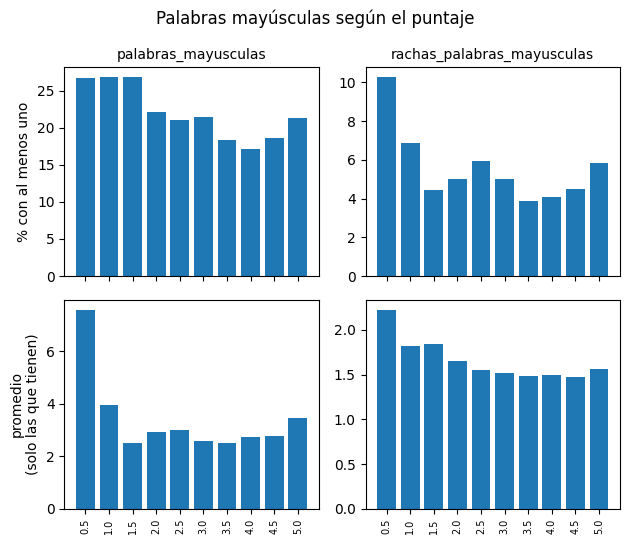

,palabras_mayusculas,rachas_palabras_mayusculas
y,,
0.5,26.8,10.3
1.0,26.9,6.9
1.5,26.9,4.4
2.0,22.1,5.0
2.5,21.1,5.9
3.0,21.5,5.0
3.5,18.4,3.9
4.0,17.2,4.1
4.5,18.6,4.5


In [94]:
def contar_palabras_mayusculas(t):
    palabras = [re.sub(r'[^\w]', '', w) for w in t.split()]
    gritada = [len(w) > 1 and w.isupper() and not w.isdigit() for w in palabras]
    rachas, seguidas = 0, 0
    for g in gritada + [False]:
        if g:
            seguidas += 1
        else:
            if seguidas >= 2:
                rachas += 1
            seguidas = 0
    return {
        'palabras_mayusculas': sum(len(w) > 1 and w.isupper() and not w.isdigit() for w in palabras),
        'rachas_palabras_mayusculas': rachas
    }

mayus = pd.DataFrame([contar_palabras_mayusculas(t) for t in df['Review']], index=df.index)
print('% de TODAS las reseñas con al menos uno:', (mayus > 0).mean().mul(100).round(1).to_dict())
tabla_mayus = graficar_por_clase(mayus, df['y'], 'Palabras mayúsculas según el puntaje')

tabla_mayus

- Las rachas de mayúsculas aparecen en el 10% de las reseñas de 0.5, contra un 4-6% en las clases medias y 6% en 5.
- Las palabras sueltas en mayúscula también son más comunes en las clases bajas (aproximadamente 27% en 0.5-1.5 contra 17-21% en 3.5-5).

Si bien hay una tendencia a que en las reseñas de baja puntuación se usen más mayúsculas, no es tanta la diferencia con el resto. Por lo que agregamos estas features para someterlas a evaluación.

In [95]:

def extraer_features_mayusculas(df_input):
        
    # Aplicamos la función para obtener los diccionarios de conteo sobre cada reseña
    conteos_mayus = [contar_palabras_mayusculas(t) if pd.notna(t) else {'palabras_mayusculas': 0, 'rachas_palabras_mayusculas': 0} for t in df_input['Review']]

    # Creamos las dos nuevas columnas booleanas (1 si está presente, 0 si no)
    df_input['palabras_mayusculas_unica'] = [1 if c['palabras_mayusculas'] > 0 else 0 for c in conteos_mayus]
    df_input['rachas_palabras_mayusculas'] = [1 if c['rachas_palabras_mayusculas'] > 0 else 0 for c in conteos_mayus]

    return df_input

df_comparacion_features = extraer_features_mayusculas(df_comparacion_features)
df_comparacion_features_val = extraer_features_mayusculas(df_comparacion_features_val)

# Mostramos las primeras filas para verificar el resultado
display(df_comparacion_features[['Review', 'palabras_mayusculas_unica', 'rachas_palabras_mayusculas']].head())
print("\nProporción de presencia de mayúsculas en el dataset (%):")
display(df_comparacion_features[['palabras_mayusculas_unica', 'rachas_palabras_mayusculas']].mean() * 100)

,Review,palabras_mayusculas_unica,rachas_palabras_mayusculas
45832,Patty Jenkins needs to start making real movie...,0,0
75499,"Only Peak Cinema Here.Director of the titanic,...",0,0
51105,One of the most gut-wrenching and claustrophob...,0,0
65405,"Well, nobody's perfect!Some Like It Hot subver...",0,0
29249,A seemingly simple story from writer/director ...,1,0



Proporción de presencia de mayúsculas en el dataset (%):


palabras_mayusculas_unica     20.05
rachas_palabras_mayusculas     5.00
dtype: float64

## 4.5 Puntaje escrito en la reseña

Algunos usuarios escriben su puntaje dentro de la reseña. Probamos extraerlo con una expresión regular:
- Un número, después `/` o "out of", y después 5, 10 o 100.
- Que el número no sea mayor que el total.
- Que no sea parte de una fecha (dd/mm/aaaa o mm/dd/aaaa) ni de un número más largo.
- Si hay varios, nos quedamos con el último, porque el puntaje suele ir al final.

Después la pasamos a la escala de 0.5 a 5 (`puntaje / total * 5`) y agregamos un indicador tiene puntaje.

Al hacer el análisis de la presencia de puntajes en la reviews, decidimos retornar dos valores:
1. Valor del puntaje encontrado normalizado a una escala 0.5-5 o, en caso de no encontrar puntaje, la media de puntajes existentes en el set de entrenamiento (evitando un potencial data leakage en caso de usar datos de prueba en el cálculo)
2. Valor booleando indicando la presencia o no de un puntaje en la review (siempre que éste sea 0, el valor del puntaje será la media descripta anteriormente)

De esta manera, podemos pensar en tener una feature que represente el valor del puntaje encontrado o, en caso de no haber ningún puntaje en la review, un valor nulo que no esté en ningún extremo de la escala para que los modelos basados en cercanía espacial (por ejemplo RVM con kernel RBF) no deban asignar un peso desproporcionado a la feature booleana para contrarestar el valor devuelto cuando no hay un puntaje explícito.

In [ ]:
patron_puntaje = re.compile(r'(?<![\d/.#(])(\d{1,3}(?:[.,]\d)?)\s*(?:/|out of)\s*(5|10|100)(?![\d/])', re.IGNORECASE)

# Cálculo de la media sobre los puntajes encontrados en el set de entrenamiento
def obtener_puntaje_crudo(t):
    if pd.isna(t):
        return np.nan
    puntajes = [float(n.replace(',', '.')) / int(d) * 5 for n, d in patron_puntaje.findall(t)
             if 0 < float(n.replace(',', '.')) <= int(d)]
    return puntajes[-1] if puntajes else np.nan

puntajes_crudos = X_train['Review'].map(obtener_puntaje_crudo)
media_puntajes_detectados = puntajes_crudos.mean()
print(f"Media de los puntajes escritos detectados en el dataset: {media_puntajes_detectados:.4f}")

def extraer_puntaje_v1(t):
    if pd.isna(t):
        return media_puntajes_detectados, 0
    
    puntajes = [float(n.replace(',', '.')) / int(d) * 5 for n, d in patron_puntaje.findall(t)
             if 0 < float(n.replace(',', '.')) <= int(d)]
    
    if puntajes:
        return puntajes[-1], 1
    else:
        return media_puntajes_detectados, 0

resultados_extraccion = df['Review'].map(extraer_puntaje_v1)
puntaje_v1 = pd.Series([r[0] for r in resultados_extraccion], index=df.index)
tiene = pd.Series([r[1] for r in resultados_extraccion], index=df.index)

puntaje_red = np.clip(np.round(puntaje_v1 * 2) / 2, 0.5, 5)
print(f'Reseñas con puntaje escrito: {tiene.mean():.1%}')
print(f'Coincide exacto con el Rating (cuando tiene escrito): {(puntaje_red[tiene == 1] == df["y"][tiene == 1]).mean():.1%}')
print(f'Error promedio (MAE) de usar la nota escrita (solo en las detectadas): {np.abs(puntaje_red[tiene == 1] - df["y"][tiene == 1]).mean():.3f} estrellas')

Media de los puntajes escritos detectados en el dataset: 4.3588
Reseñas con puntaje escrito (tiene_puntaje == 1): 3.3%
Coincide exacto con el Rating (cuando tiene escrito): 74.2%
Error promedio (MAE) de usar la nota escrita (solo en las detectadas): 0.254 estrellas


El puntaje escrito aparece en un 3.3% de las reseñas y coincide exacto con el rating en el 74.2% de las veces.

Si bien es poca la cantidad de reseñas en las que aparece este patrón, la relación entre los puntajes explícitos encontrados y los valores de sus respectivos ratings es información que puede resultar útil para el modelo. Es por esto que agregamos ambas features (el puntaje detectado normalizado en una escala del 0.5 al 5 y el booleano que indica la presencia de un puntaje explícito) para evualuar su efectividad de manera conjunta.

Este es el primer caso en el que usamos dos features diferentes para reprentar una única característica del dataset, de manera que cada una de las features por separado son mucho menos útiles que la combinación de ambas ("tiene_puntaje_escrito" solo aporta a la predicción indirectamente, indicando si "puntaje_escrito" debe ser considerado o no). El método utilizado para evaluar ambas features en conjunto se detalla más adelante en el capítulo sobre la selección de features

In [ ]:
puntajes_encontrados = df_comparacion_features['Review'].map(extraer_puntaje_v1)
puntajes_encontrados_val = df_comparacion_features_val['Review'].map(extraer_puntaje_v1)

df_comparacion_features['puntaje_escrito'] = [r[0] for r in puntajes_encontrados]
df_comparacion_features['tiene_puntaje_escrito'] = [r[1] for r in puntajes_encontrados]

df_comparacion_features_val['puntaje_escrito'] = [r[0] for r in puntajes_encontrados_val]
df_comparacion_features_val['tiene_puntaje_escrito'] = [r[1] for r in puntajes_encontrados_val]

display(df_comparacion_features[df_comparacion_features['tiene_puntaje'] == 1][['Review', 'puntaje_escrito', 'tiene_puntaje']].head())

print("\nDistribución del feature booleano 'tiene_puntaje':")
print(df_comparacion_features['tiene_puntaje'].value_counts())

print("\nEstadísticas del puntaje escrito (con nulos imputados con la media):")
print(df_comparacion_features['puntaje_escrito'].describe())

,Review,puntaje_escrito,tiene_puntaje
54374,Angelopoulos has a extremely unique visionary ...,3.5,1
24523,:trophy:93%Studio Ghibli list coming:SOON_arro...,5.0,1
46819,Kinda embarrassed to admit that this is my fir...,5.0,1
26321,completed Bela Tarr's 7 Hour 19 Minute masterp...,4.9,1
19869,10/10Shoutout to @potionsocks for the request....,5.0,1



Distribución del feature booleano 'tiene_puntaje':
tiene_puntaje
0    29025
1      975
Name: count, dtype: int64

Estadísticas del puntaje escrito (con nulos imputados con la media):
count    30000.000000
mean         4.358585
std          0.159220
min          0.050000
25%          4.358821
50%          4.358821
75%          4.358821
max          5.000000
Name: puntaje_escrito, dtype: float64


## 4.6 Señales de Ironía

La ironía es uno de los problemas abiertos del análisis de sentimiento. No hay una forma simple de detectarla, pero probamos algunos posibles indicadores:
- Comillas alrededor de palabras cortas.
- Risas y emojis ironicos
- Palabras alargadas dan a exageración.


% de TODAS las reseñas con al menos uno: {'comillas_cortas': 13.5, 'risas': 1.4, 'alargadas': 1.9}


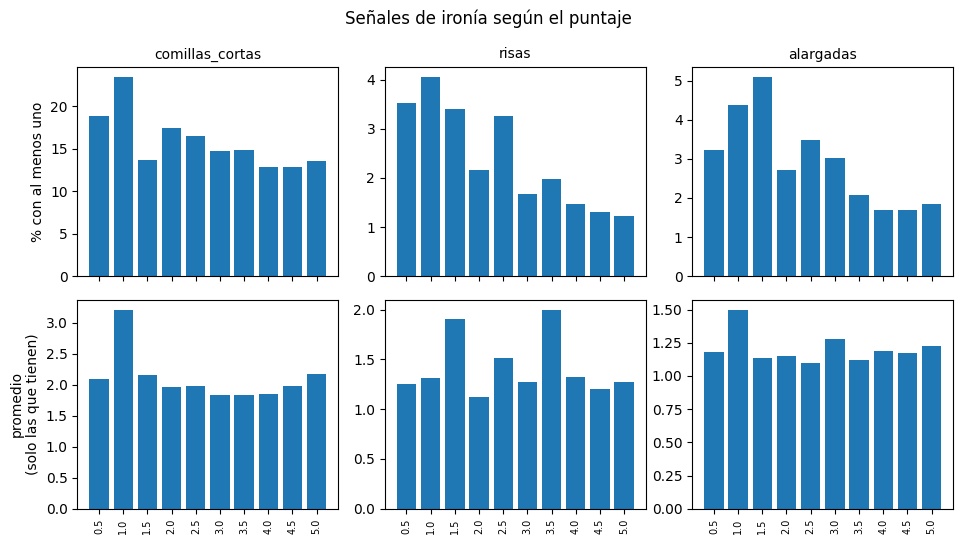

,comillas_cortas,risas,alargadas
y,,,
0.5,18.8,3.5,3.2
1.0,23.4,4.1,4.4
1.5,13.6,3.4,5.1
2.0,17.4,2.2,2.7
2.5,16.5,3.3,3.5
3.0,14.7,1.7,3.0
3.5,14.8,2.0,2.1
4.0,12.8,1.5,1.7
4.5,12.8,1.3,1.7


In [98]:

def senales_ironia(t):
    tl = t.lower()
    ws = re.findall(r"[a-z']+", tl)
    return {
        'comillas_cortas': len(re.findall(r'(?:^|\s)["“][A-Za-z][^"“”]{0,18}["”]', t)),
        'risas': len(re.findall(r'\b(?:lol|lmao|lmfao|rofl|a?(?:ha){2,}h?)\b', tl)) + sum(t.count(e) for e in '😂💀🤡🙄🤣'),
        'alargadas': len(re.findall(r'\b\w*([a-hj-vx-z])\1{2,}\w*\b', tl))
    }

ironia = pd.DataFrame([senales_ironia(t) for t in df['Review']], index=df.index)
conteos_ironia = ['comillas_cortas', 'risas', 'alargadas']
print('% de TODAS las reseñas con al menos uno:', (ironia[conteos_ironia] > 0).mean().mul(100).round(1).to_dict())
tabla_ironia = graficar_por_clase(ironia[conteos_ironia], df['y'], 'Señales de ironía según el puntaje')
tabla_ironia

Risas, comillas y palabras alargadas aparecen más en las clases bajas. Son diferencias reales pero chicas, y cada señal aparece en pocas reseñas. Por lo que las agregamos como features para probar su efectividad.


In [99]:
def extraer_features_ironia(df_input):
    # Aplicamos la función senales_ironia ya definida en cada reseña
    conteos_ironia = [senales_ironia(t) if pd.notna(t) else {'comillas_cortas': 0, 'risas': 0, 'alargadas': 0} for t in df_input['Review']]

    # Creamos las tres nuevas columnas booleanas (1 si está presente, 0 si no)
    df_input['comillas_cortas'] = [1 if c['comillas_cortas'] > 0 else 0 for c in conteos_ironia]
    df_input['risas'] = [1 if c['risas'] > 0 else 0 for c in conteos_ironia]
    df_input['palabras_alargadas'] = [1 if c['alargadas'] > 0 else 0 for c in conteos_ironia]

    return df_input

df_comparacion_features = extraer_features_ironia(df_comparacion_features)
df_comparacion_features_val = extraer_features_ironia(df_comparacion_features_val)

# Mostramos las primeras filas para verificar el resultado
display(df_comparacion_features[['Review', 'comillas_cortas', 'risas', 'palabras_alargadas']].head())
print("\nProporción de presencia de señales de ironía en el dataset (%):")
display(df_comparacion_features[['comillas_cortas', 'risas', 'palabras_alargadas']].mean() * 100)

,Review,comillas_cortas,risas,palabras_alargadas
45832,Patty Jenkins needs to start making real movie...,0,0,0
75499,"Only Peak Cinema Here.Director of the titanic,...",0,0,0
51105,One of the most gut-wrenching and claustrophob...,0,0,0
65405,"Well, nobody's perfect!Some Like It Hot subver...",1,0,0
29249,A seemingly simple story from writer/director ...,0,0,1



Proporción de presencia de señales de ironía en el dataset (%):


comillas_cortas       13.443333
risas                  1.090000
palabras_alargadas     1.916667
dtype: float64

## 4.7 Nombres propios: títulos de películas, directores, actores.

Decidimos analizar como influye la presencia de nombres propios (generalmente en referencia a actores o directores de las películas reseñadas) en la distribución del los puntajes de la reseña.

### TODO: Repensar el análisis para que termine en un tiempo razonable o eliminar el capítulo

In [100]:

'''
# Cargamos el modelo (igual que lo tenías)
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
except OSError:
    import os
    os.system("python -m spacy download en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

# Función auxiliar para procesar el doc ya generado
def contiene_entidad_objetivo(doc):
    for ent in doc.ents:
        if ent.label_ in ['PERSON', 'ORG', 'WORK_OF_ART']:
            return 1 # Devuelve 1 apenas encuentra la primera, ahorrando procesamiento
    return 0

print("Analizando entidades en las reseñas (modo batch optimizado)...")

# Preparar los textos asegurando que sean strings (manejo de nulos)
textos = df['Review'].fillna("").astype(str).tolist()

# Magia de spaCy: nlp.pipe procesa en bloques (batch_size)
# Iteramos sobre los documentos ya procesados de forma mucho más eficiente.
resultados = [{'nombres_propios': contiene_entidad_objetivo(doc)} for doc in nlp.pipe(textos, batch_size=500)]

# Generar el DataFrame asegurando el índice original
nombres_features = pd.DataFrame(resultados, index=df.index)

print("¡Análisis completado!")

# Graficamos los resultados con la función existente
tabla_nombres = graficar_por_clase(nombres_features, df['y'], 'Presencia de nombres propios según el puntaje')
display(tabla_nombres)

# Agregamos la columna booleana al dataset de comparación
df_comparacion_features['nombres_propios'] = nombres_features['nombres_propios']
'''

'\n# Cargamos el modelo (igual que lo tenías)\ntry:\n    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])\nexcept OSError:\n    import os\n    os.system("python -m spacy download en_core_web_sm")\n    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])\n\n# Función auxiliar para procesar el doc ya generado\ndef contiene_entidad_objetivo(doc):\n    for ent in doc.ents:\n        if ent.label_ in [\'PERSON\', \'ORG\', \'WORK_OF_ART\']:\n            return 1 # Devuelve 1 apenas encuentra la primera, ahorrando procesamiento\n    return 0\n\nprint("Analizando entidades en las reseñas (modo batch optimizado)...")\n\n# Preparar los textos asegurando que sean strings (manejo de nulos)\ntextos = df[\'Review\'].fillna("").astype(str).tolist()\n\n# Magia de spaCy: nlp.pipe procesa en bloques (batch_size)\n# Iteramos sobre los documentos ya procesados de forma mucho más eficiente.\nresultados = [{\'nombres_propios\': contiene_entidad_objetivo(doc)} for doc in nl

In [101]:
df_comparacion_features

,Review,Status_Desconocido,Status_Rewatched,Status_Watched,!_unico,!_multiple,?_unico,?_multiple,palabras_mayusculas_unica,rachas_palabras_mayusculas,puntaje_escrito,comillas_cortas,risas,palabras_alargadas
45832,Patty Jenkins needs to start making real movie...,0,0,1,1,0,0,0,0,0,0.0,0,0,0
75499,"Only Peak Cinema Here.Director of the titanic,...",0,0,1,0,0,0,0,0,0,0.0,0,0,0
51105,One of the most gut-wrenching and claustrophob...,0,0,1,1,0,0,0,0,0,0.0,0,0,0
65405,"Well, nobody's perfect!Some Like It Hot subver...",0,0,1,1,0,0,0,0,0,0.0,1,0,0
29249,A seemingly simple story from writer/director ...,0,0,1,1,0,1,0,1,0,0.0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61979,Um dos ápices conceituais do cinema moderno e ...,0,1,0,0,0,0,0,0,0,0.0,0,0,0
52343,You don't always need the biggest budget or th...,0,0,1,0,0,0,0,0,0,0.0,1,0,0
48308,Herculean. Cornball in the hands of almost any...,0,1,0,0,0,0,0,0,0,0.0,0,0,0
10803,"""The men died perfectly.""Stanley Kubrick's Pat...",0,0,1,0,0,1,0,1,0,0.0,0,0,0


# Selección de features

In [102]:
from sklearn.feature_selection import SequentialFeatureSelector

# vamos a probar con todas las features tabulares que armamos en el proceso de feature engineering (todas menos review)
cols_candidatas = [c for c in df_comparacion_features.columns if c != 'Review']
X_tr_tab, X_vl_tab = df_comparacion_features[cols_candidatas], df_comparacion_features_val[cols_candidatas]

sfs = SequentialFeatureSelector(
    Ridge(alpha=1.0),
    n_features_to_select='auto',
    tol=0.0005,
    direction='forward',
    scoring='neg_mean_absolute_error',
    cv=KFold(5, shuffle=True, random_state=42),
    n_jobs=-1,
).fit(X_tr_tab, y_train_sub)

# aca vemos cuales son el subset optimo segun el selector
cols_opt = list(X_tr_tab.columns[sfs.get_support()])
print(
    f'Features seleccionadas ({len(cols_opt)}/{len(cols_candidatas)}):'
    f' {cols_opt}'
)

# vectorizamos y escalamos para que todas las features (las resultantes de vectorizar con tf idf y las resultantes del feature engineering) esten en escala
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
X_tr_txt = vec.fit_transform(df_comparacion_features['Review'])
X_vl_txt = vec.transform(X_val['Review'])

def evaluar(X_tr, X_vl, y_tr, y_vl):
  m = Ridge(alpha=1.0).fit(X_tr, y_tr)
  y_pred = np.round(np.clip(m.predict(X_vl), 0.5, 5.0) * 2) / 2
  y_vl_cat = (y_vl.to_numpy() * 2).round().astype(int)
  y_pred_cat = (y_pred * 2).round().astype(int)
  return {
      'MAE': round(mean_absolute_error(y_vl, y_pred), 4),
      'Accuracy': round(accuracy_score(y_vl_cat, y_pred_cat), 4),
  }


scaler_all = StandardScaler()
X_tr_tab_all_s = scaler_all.fit_transform(X_tr_tab[cols_candidatas])
X_vl_tab_all_s = scaler_all.transform(X_vl_tab[cols_candidatas])

scaler_opt = StandardScaler()
X_tr_tab_opt_s = scaler_opt.fit_transform(X_tr_tab[cols_opt])
X_vl_tab_opt_s = scaler_opt.transform(X_vl_tab[cols_opt])

# Definición de las tres configuraciones
configs = {
    'Solo TF-IDF': (X_tr_txt, X_vl_txt),
    'TF-IDF + Features óptimas (SFS)': (
        hstack([X_tr_txt, X_tr_tab_opt_s]),
        hstack([X_vl_txt, X_vl_tab_opt_s]),
    ),
    'TF-IDF + Todas las tabulares': (
        hstack([X_tr_txt, X_tr_tab_all_s]),
        hstack([X_vl_txt, X_vl_tab_all_s]),
    ),
}

res = {
    nombre: {
        'Features': X_tr.shape[1],
        **evaluar(X_tr, X_vl, y_train_sub, y_val),
    }
    for nombre, (X_tr, X_vl) in configs.items()
}

df_comparacion = pd.DataFrame(res).T
print(df_comparacion)

Features seleccionadas (2/13): ['Status_Rewatched', 'risas']
                                 Features     MAE  Accuracy
Solo TF-IDF                      150069.0  0.4194    0.3711
TF-IDF + Features óptimas (SFS)  150071.0  0.4017    0.3979
TF-IDF + Todas las tabulares     150082.0  0.4014    0.3988
